In [23]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [2]:
transform = transforms.ToTensor()

In [6]:
!pwd

/content


In [7]:
!mkdir data

In [14]:
# root: 데이터 저장할 위치
# download: True면 저장함
X_train = datasets.MNIST(root='/content/data', train=True, download=True, transform=transform)
X_test = datasets.MNIST(root='/content/data', train=False, download=True, transform=transform)

In [16]:
print(X_train)
print(X_test)
print(len(X_train))
print(len(X_test))

Dataset MNIST
    Number of datapoints: 60000
    Root location: /content/data
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset MNIST
    Number of datapoints: 10000
    Root location: /content/data
    Split: Test
    StandardTransform
Transform: ToTensor()
60000
10000


In [17]:
X_train.classes

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

In [18]:
X_train.class_to_idx

{'0 - zero': 0,
 '1 - one': 1,
 '2 - two': 2,
 '3 - three': 3,
 '4 - four': 4,
 '5 - five': 5,
 '6 - six': 6,
 '7 - seven': 7,
 '8 - eight': 8,
 '9 - nine': 9}

In [21]:
X_train.data.shape

torch.Size([60000, 28, 28])

In [29]:
print(X_train.targets)
print(len(X_train.targets))

tensor([5, 0, 4,  ..., 5, 6, 8])
60000


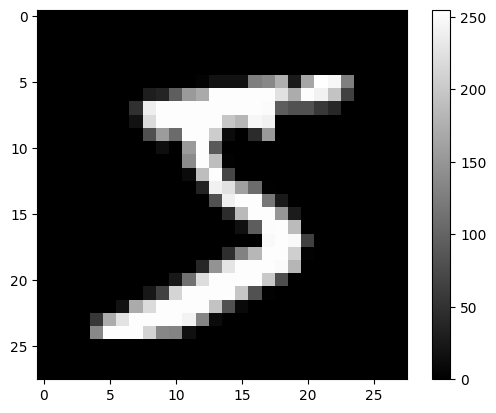

In [25]:
plt.imshow(X_train.data[0], cmap='gray')
plt.colorbar()

In [26]:
# DataLoader: 배치 단위로 학습시키는 데 유용함
# 배치를 비복원추출할 때 자동으로 transform을 거침
# ToTensor의 역할
# 1. tensor로 바꾸고
# 2. 개체행렬로 바꾸고
# 3. 0~1 사이로 바꿈(int -> float)
batch_size = 32
train = DataLoader(X_train, batch_size=batch_size, shuffle=True)
test = DataLoader(X_test, batch_size=batch_size, shuffle=True)

In [30]:
train.dataset

Dataset MNIST
    Number of datapoints: 60000
    Root location: /content/data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [31]:
x_batch, y_batch = next(iter(train))
print(x_batch.shape)
print(y_batch.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32])


tensor(7)


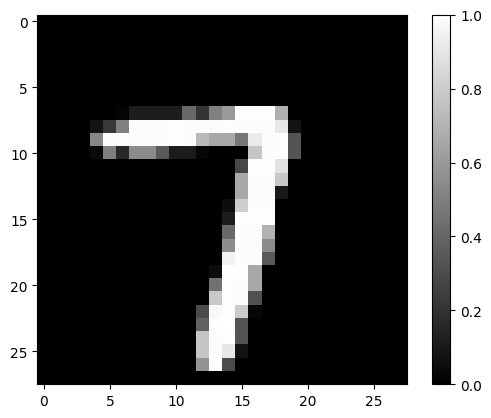

In [33]:
plt.imshow(torch.squeeze(x_batch[0]), cmap='gray')
plt.colorbar()
print(y_batch[0])